# Pie Chart

**Family:** Part-to-whole &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Part-to-whole:* Show how a single entity breaks down into its components.

## Design purpose

A circle divided into slices that add up to 100%. It answers one question: roughly what share of the whole is each part? People judge angles and areas less accurately than lengths, so a pie is for a rough picture, not precise comparison.

## When to use

- Show a simple part-to-whole split with few slices (≤ 6, ideally 2–4)
- Show that one part is clearly dominant (about half or more)
- General-audience communication where the 'slices of a whole' metaphor helps

## Avoid when

- There are more than 6 slices (fold the small ones into 'Other' or use a bar chart)
- Slices are close in size and the difference matters
- Comparing several pies side by side (use a 100% stacked bar)
- The parts don't add up to a meaningful whole
- 3-D or exploded pies, which distort the angles

## Alternatives

- Bar chart
- Donut chart
- Waffle chart
- 100% stacked bar

## Design tips

- Start the largest slice at 12 o'clock and go clockwise in descending order
- Label slices directly and drop the legend
- Separate slices with a thin surface-colored gap

## Example

Share of web traffic by source (5 slices, the smallest folded into 'Other').

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
pio.templates["vizlib"] = go.layout.Template(layout=dict(
    colorway=PALETTE, font=dict(family="Helvetica, Arial, sans-serif", size=13, color="#0b0b0b"),
    paper_bgcolor="#fcfcfb", plot_bgcolor="#fcfcfb", title=dict(x=0.02, xanchor="left"),
    xaxis=dict(gridcolor="#e6e5e1", linecolor="#c9c8c3", zeroline=False),
    yaxis=dict(gridcolor="#e6e5e1", linecolor="#c9c8c3", zeroline=False),
))
pio.templates.default = "plotly_white+vizlib"
pio.renderers.default = "plotly_mimetype+notebook_connected"

### Data

In [2]:
raw = pd.Series({"Organic search": 41, "Direct": 24, "Social": 14, "Referral": 11,
                 "Email": 6, "Paid": 2.5, "Affiliates": 1.5})
# Keep at most 5 named slices; fold the tail into "Other"
top = raw.nlargest(4)
s = pd.concat([top, pd.Series({"Other": raw.drop(top.index).sum()})])
s

Organic search    41.0
Direct            24.0
Social            14.0
Referral          11.0
Other             10.0
dtype: float64

### Plot

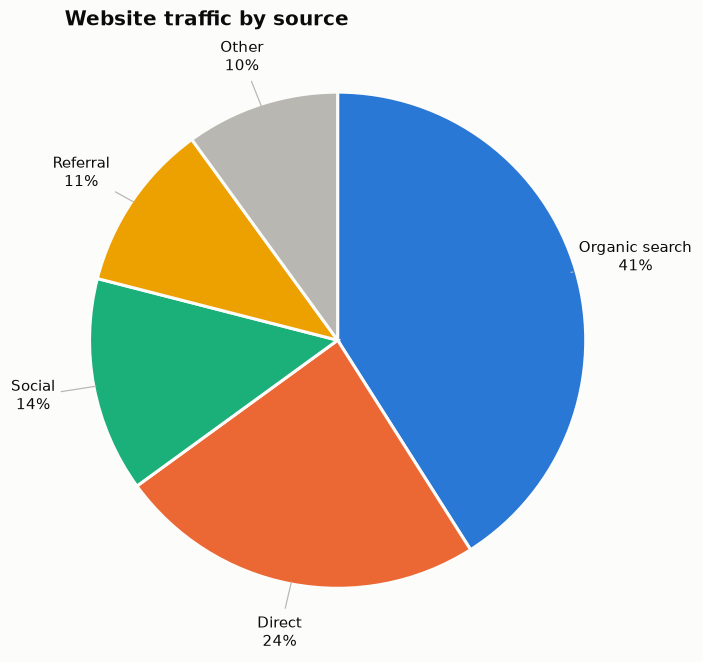

In [3]:
fig, ax = plt.subplots(figsize=(6.5, 6.5))
colors = PALETTE[:len(s) - 1] + [GRAY]
wedges, _ = ax.pie(s.values, colors=colors, startangle=90, counterclock=False,
                   wedgeprops=dict(edgecolor="#fcfcfb", linewidth=2))
for w, (name, v) in zip(wedges, s.items()):
    ang = np.deg2rad((w.theta1 + w.theta2) / 2)
    x, y = np.cos(ang), np.sin(ang)
    ax.annotate(f"{name}\n{v:.0f}%", xy=(0.98 * x, 0.98 * y), xytext=(1.25 * x, 1.2 * y),
                ha="center", va="center", fontsize=10,
                arrowprops=dict(arrowstyle="-", color="#b8b7b1", linewidth=0.8))
ax.set_title("Website traffic by source")
ax.axis("equal")
fig.tight_layout()
plt.show()

## How to read it

Organic search brings in about two-fifths of traffic. Organic search and direct together make up about two-thirds.

## The same chart in other libraries

Each version uses the example data above. Pick the library that fits your stack: matplotlib/seaborn for static and print figures, plotly for interactive HTML, Altair for concise declarative specs.

### plotly

In [4]:
import plotly.express as px
fig = px.pie(names=s.index, values=s.values, color_discrete_sequence=PALETTE[:len(s) - 1] + ["#b8b7b1"],
             title="Website traffic by source")
fig.update_traces(sort=False, direction="clockwise", textinfo="label+percent",
                  marker=dict(line=dict(color="#fcfcfb", width=2)))
fig.update_layout(showlegend=False)
fig.show()

---
Standalone script: [`pie_chart.py`](pie_chart.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)